# Practical 5 - Amazon Content-Based Recommender System

## Dataset

Amazon Reviews 2023, **All_Beauty** category.

Place these two files in:

`/content/drive/MyDrive/Classes/MCA3/RS/Amazon_Reviews`

- `All_Beauty.jsonl.gz`
- `meta_All_Beauty.jsonl.gz`

## Aim

To build a content-based recommender using product metadata, represent products with TF-IDF, calculate cosine similarity manually, build rating-weighted user profiles, generate Top-N recommendations, explain recommendations, and evaluate with ranking metrics.


## 1. Mount Google Drive


In [1]:
# 1. Mount Google Drive

from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


## 2. Import libraries


In [3]:
# 2. Import libraries

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.sparse import csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer

## 3. Settings

In [ ]:
# 3. Settings

DATA_FOLDER = "/content/drive/MyDrive/RS/Content/Amazon_Reviews"

REVIEWS_FILE = os.path.join(
    DATA_FOLDER,
    "All_Beauty.jsonl.gz"
)

METADATA_FILE = os.path.join(
    DATA_FOLDER,
    "meta_All_Beauty.jsonl.gz"
)

TOP_N = 10
RANKING_K = 10
RELEVANCE_THRESHOLD = 4.0

# To keep the practical fast enough for Colab/class use.
MAX_PRODUCTS = 5000
MIN_USER_INTERACTIONS = 5

TFIDF_MIN_DF = 2
TFIDF_MAX_FEATURES = 30000

MAX_EVAL_USERS = 300
EVAL_RANDOM_STATE = 42

DEMO_USER_INDEX = 0
DEMO_PRODUCT_INDEX = 0

## 4. Check that the two dataset files exist


In [6]:
# 4. Check that the two dataset files exist

for path in [
    REVIEWS_FILE,
    METADATA_FILE
]:
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"File not found: {path}"
        )

print("Amazon dataset folder:")
print(DATA_FOLDER)

Amazon dataset folder:
/content/drive/MyDrive/Classes/MCA3/RS/Amazon_Reviews


## 5. Load Amazon review and metadata files


In [7]:
# 5. Load Amazon review and metadata files

# pandas can read line-delimited JSON directly from .gz files.

# Review fields used:
# user_id, parent_asin, rating, timestamp

# Metadata fields used:
# parent_asin, title, main_category, store,
# categories, features, description

reviews = pd.read_json(
    REVIEWS_FILE,
    lines=True,
    compression="gzip"
)

metadata = pd.read_json(
    METADATA_FILE,
    lines=True,
    compression="gzip"
)

print("\n" + "=" * 70)
print("AMAZON REVIEWS 2023 - ALL BEAUTY")
print("=" * 70)

print("Reviews shape :", reviews.shape)
print("Metadata shape:", metadata.shape)

print("\nReview sample")
display(reviews.head())

print("\nMetadata sample")
display(metadata.head())


AMAZON REVIEWS 2023 - ALL BEAUTY
Reviews shape : (701528, 10)
Metadata shape: (112590, 14)

Review sample


,rating,title,text,images,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase
0,5,Such a lovely scent but not overpowering.,This spray is really nice. It smells really go...,[],B00YQ6X8EO,B00YQ6X8EO,AGKHLEW2SOWHNMFQIJGBECAF7INQ,2020-05-05 14:08:48.923,0,True
1,4,Works great but smells a little weird.,"This product does what I need it to do, I just...",[],B081TJ8YS3,B081TJ8YS3,AGKHLEW2SOWHNMFQIJGBECAF7INQ,2020-05-04 18:10:55.070,1,True
2,5,Yes!,"Smells good, feels great!",[],B07PNNCSP9,B097R46CSY,AE74DYR3QUGVPZJ3P7RFWBGIX7XQ,2020-05-16 21:41:06.052,2,True
3,1,Synthetic feeling,Felt synthetic,[],B09JS339BZ,B09JS339BZ,AFQLNQNQYFWQZPJQZS6V3NZU4QBQ,2022-01-28 18:13:50.220,0,True
4,5,A+,Love it,[],B08BZ63GMJ,B08BZ63GMJ,AFQLNQNQYFWQZPJQZS6V3NZU4QBQ,2020-12-30 10:02:43.534,0,True



Metadata sample


,main_category,title,average_rating,rating_number,features,description,price,images,videos,store,categories,details,parent_asin,bought_together
0,All Beauty,"Howard LC0008 Leather Conditioner, 8-Ounce (4-...",4.8,10,[],[],NaN,[{'thumb': 'https://m.media-amazon.com/images/...,[],Howard Products,[],{'Package Dimensions': '7.1 x 5.5 x 3 inches; ...,B01CUPMQZE,NaN
1,All Beauty,Yes to Tomatoes Detoxifying Charcoal Cleanser ...,4.5,3,[],[],NaN,[{'thumb': 'https://m.media-amazon.com/images/...,[],Yes To,[],"{'Item Form': 'Powder', 'Skin Type': 'Acne Pro...",B076WQZGPM,NaN
2,All Beauty,Eye Patch Black Adult with Tie Band (6 Per Pack),4.4,26,[],[],NaN,[{'thumb': 'https://m.media-amazon.com/images/...,[],Levine Health Products,[],{'Manufacturer': 'Levine Health Products'},B000B658RI,NaN
3,All Beauty,"Tattoo Eyebrow Stickers, Waterproof Eyebrow, 4...",3.1,102,[],[],NaN,[{'thumb': 'https://m.media-amazon.com/images/...,[],Cherioll,[],"{'Brand': 'Cherioll', 'Item Form': 'Powder', '...",B088FKY3VD,NaN
4,All Beauty,Precision Plunger Bars for Cartridge Grips – 9...,4.3,7,"[Material: 304 Stainless Steel; Brass tip, Len...",[The Precision Plunger Bars are designed to wo...,NaN,[{'thumb': 'https://m.media-amazon.com/images/...,[],Precision,[],{'UPC': '644287689178'},B07NGFDN6G,NaN


## 6. Keep only the columns needed for this practical


In [8]:
# 6. Keep only the columns needed for this practical

required_review_columns = {
    "user_id",
    "parent_asin",
    "rating",
    "timestamp"
}

required_meta_columns = {
    "parent_asin",
    "title",
    "main_category",
    "store",
    "categories",
    "features",
    "description"
}

if not required_review_columns.issubset(
    reviews.columns
):
    raise ValueError(
        "The review file does not contain all required columns."
    )

if not required_meta_columns.issubset(
    metadata.columns
):
    raise ValueError(
        "The metadata file does not contain all required columns."
    )

reviews = reviews[
    [
        "user_id",
        "parent_asin",
        "rating",
        "timestamp"
    ]
].copy()

metadata = metadata[
    [
        "parent_asin",
        "title",
        "main_category",
        "store",
        "categories",
        "features",
        "description"
    ]
].copy()

## 7. Remove incomplete rows


In [9]:
# 7. Remove incomplete rows

reviews = reviews.dropna(
    subset=[
        "user_id",
        "parent_asin",
        "rating",
        "timestamp"
    ]
)

metadata = metadata.dropna(
    subset=[
        "parent_asin",
        "title"
    ]
)

# Keep one metadata row per parent product.
metadata = metadata.drop_duplicates(
    subset=["parent_asin"]
)

print("\nClean reviews :", reviews.shape)
print("Clean metadata:", metadata.shape)


Clean reviews : (701528, 4)
Clean metadata: (112590, 7)


## 8. Collapse repeated user-product interactions


In [10]:
# 8. Collapse repeated user-product interactions

# If the same user reviewed the same parent product more than
# once, keep the latest interaction.

reviews = (
    reviews
    .sort_values("timestamp")
    .drop_duplicates(
        subset=[
            "user_id",
            "parent_asin"
        ],
        keep="last"
    )
)

print(
    "\nUnique user-product interactions:",
    len(reviews)
)


Unique user-product interactions: 693929


## 9. Restrict the experiment to the most-reviewed products


In [11]:
# 9. Restrict the experiment to the most-reviewed products

# The raw All_Beauty category is much larger than MovieLens
# Small. Keeping the most-reviewed products makes TF-IDF and
# ranking evaluation practical in a classroom notebook.

product_popularity = (
    reviews["parent_asin"]
    .value_counts()
)

selected_products = (
    product_popularity
    .head(MAX_PRODUCTS)
    .index
)

reviews = reviews[
    reviews["parent_asin"].isin(
        selected_products
    )
].copy()

metadata = metadata[
    metadata["parent_asin"].isin(
        selected_products
    )
].copy()

## 10. Keep users with enough interaction history


In [12]:
# 10. Keep users with enough interaction history

# A content profile built from only one or two items is weak.
# Requiring at least five interactions also makes chronological
# holdout evaluation more meaningful.

user_counts = (
    reviews["user_id"]
    .value_counts()
)

active_users = user_counts[
    user_counts >= MIN_USER_INTERACTIONS
].index

reviews = reviews[
    reviews["user_id"].isin(
        active_users
    )
].copy()

# Remove products that disappeared after user filtering.
remaining_products = reviews[
    "parent_asin"
].unique()

metadata = metadata[
    metadata["parent_asin"].isin(
        remaining_products
    )
].copy()

reviews = reviews[
    reviews["parent_asin"].isin(
        metadata["parent_asin"]
    )
].copy()

print("\nAfter classroom filtering")
print("Users   :", reviews["user_id"].nunique())
print("Products:", reviews["parent_asin"].nunique())
print("Ratings :", len(reviews))


After classroom filtering
Users   : 159
Products: 495
Ratings : 1167


## 11. Helper for converting list-like metadata to text


In [13]:
# 11. Helper for converting list-like metadata to text

def list_to_text(value):
    """
    Convert Amazon metadata values such as lists of categories,
    features, or description lines into one text string.
    """

    if isinstance(value, list):
        return " ".join(
            str(x)
            for x in value
            if pd.notna(x)
        )

    if pd.isna(value):
        return ""

    return str(value)

## 12. Prepare product content


In [14]:
# 12. Prepare product content

# Content fields:
# title + main category + store + categories +
# product features + product description

metadata["main_category_text"] = (
    metadata["main_category"]
    .fillna("")
    .astype(str)
)

metadata["store_text"] = (
    metadata["store"]
    .fillna("")
    .astype(str)
)

metadata["categories_text"] = (
    metadata["categories"]
    .apply(list_to_text)
)

metadata["features_text"] = (
    metadata["features"]
    .apply(list_to_text)
)

metadata["description_text"] = (
    metadata["description"]
    .apply(list_to_text)
)

metadata["content"] = (
    metadata["title"].fillna("").astype(str)
    + " "
    + metadata["main_category_text"]
    + " "
    + metadata["store_text"]
    + " "
    + metadata["categories_text"]
    + " "
    + metadata["features_text"]
    + " "
    + metadata["description_text"]
)

metadata["content"] = (
    metadata["content"]
    .str.lower()
    .str.replace(
        r"\s+",
        " ",
        regex=True
    )
    .str.strip()
)

metadata = (
    metadata
    .reset_index(drop=True)
)

print("\nPrepared product content")
display(
    metadata[
        [
            "parent_asin",
            "title",
            "main_category",
            "store",
            "content"
        ]
    ].head(10)
)


Prepared product content


,parent_asin,title,main_category,store,content
0,B08LYT4Q2X,Organic Sweet Almond Oil and Fractionated Coco...,All Beauty,Shiny Leaf,organic sweet almond oil and fractionated coco...
1,B089CSF11Y,"Empty Brown Glass Spray Bottles2-Pack, Refilla...",All Beauty,Cherry,"empty brown glass spray bottles2-pack, refilla..."
2,B08MVFKSQ8,MoYo Natural Labs 8 oz Spray Bottles Fine Mist...,All Beauty,MoYo Natural Labs,moyo natural labs 8 oz spray bottles fine mist...
3,B016MNB4HQ,Vitamin C Serum for Face - C Booster With Hyal...,All Beauty,None,vitamin c serum for face - c booster with hyal...
4,B00TAHJOYC,19pc LA Girl Gel Glide Eyeliner Pencil set of ...,All Beauty,L.A. Girl,19pc la girl gel glide eyeliner pencil set of ...
5,B084GGP5SQ,Shower Jellies (Blueberry Cobbler),All Beauty,Bella and Bear,shower jellies (blueberry cobbler) all beauty ...
6,B09GNXK3N1,"Reusable Shower Cap for Women – Leakproof, Non...",All Beauty,SMPL objects,"reusable shower cap for women – leakproof, non..."
7,B07KDYT8XY,"SheCotton Premium Cotton Rounds for Face, Lint...",All Beauty,She Cotton,"shecotton premium cotton rounds for face, lint..."
8,B00TNREDHW,Detangling Brush Pink Hair Brush For Women Bes...,All Beauty,Hair Glider,detangling brush pink hair brush for women bes...
9,B001MP47WE,"Supernail China Silk Wrap, 72 Inch",All Beauty,SuperNail,"supernail china silk wrap, 72 inch all beauty ..."


## 13. Visualize the most common stores/brands


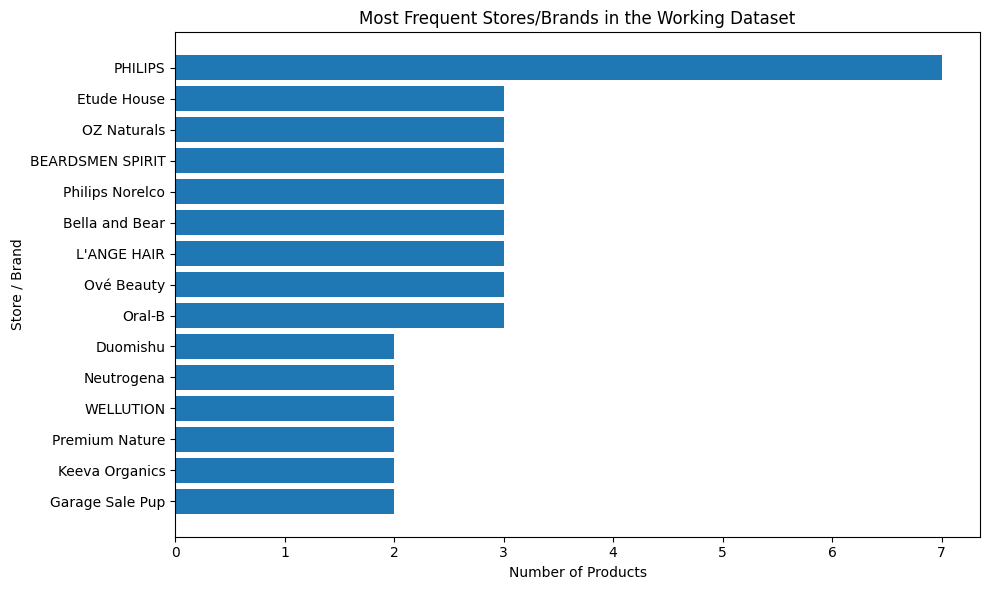

In [15]:
# 13. Visualize the most common stores/brands

store_counts = (
    metadata["store_text"]
    .replace("", np.nan)
    .dropna()
    .value_counts()
    .head(15)
    .sort_values()
)

if len(store_counts) > 0:

    plt.figure(figsize=(10, 6))

    plt.barh(
        store_counts.index,
        store_counts.values
    )

    plt.xlabel("Number of Products")
    plt.ylabel("Store / Brand")
    plt.title("Most Frequent Stores/Brands in the Working Dataset")

    plt.tight_layout()
    plt.show()

## 14. Convert product content into TF-IDF vectors


In [16]:
# 14. Convert product content into TF-IDF vectors

tfidf = TfidfVectorizer(
    stop_words="english",
    min_df=TFIDF_MIN_DF,
    max_features=TFIDF_MAX_FEATURES,
    lowercase=True
)

item_features = tfidf.fit_transform(
    metadata["content"]
)

feature_names = (
    tfidf
    .get_feature_names_out()
)

print("\nTF-IDF matrix shape:")
print(item_features.shape)

print(
    "Number of TF-IDF features:",
    len(feature_names)
)


TF-IDF matrix shape:
(495, 2886)
Number of TF-IDF features: 2886


## 15. Build product ID <-> matrix-row mappings


In [17]:
# 15. Build product ID <-> matrix-row mappings

product_ids = (
    metadata[
        "parent_asin"
    ]
    .to_numpy()
)

product_to_row = {
    product_id: row
    for row, product_id
    in enumerate(product_ids)
}

## 16. Manual cosine similarity


In [18]:
# 16. Manual cosine similarity

def manual_cosine_scores(
    query_vector,
    candidate_matrix
):
    """
    Calculate cosine similarity between one sparse query vector
    and every row of a sparse candidate matrix.

    query_vector:
        shape (1, n_features)

    candidate_matrix:
        shape (n_products, n_features)

    returns:
        NumPy array containing one cosine score per product.
    """

    query_vector = csr_matrix(
        query_vector
    )

    candidate_matrix = csr_matrix(
        candidate_matrix
    )

    dot_products = (
        candidate_matrix
        @ query_vector.T
    ).toarray().ravel()

    query_norm = np.sqrt(
        query_vector
        .multiply(query_vector)
        .sum()
    )

    candidate_norms = np.sqrt(
        candidate_matrix
        .multiply(candidate_matrix)
        .sum(axis=1)
    ).A1

    denominators = (
        candidate_norms
        * query_norm
    )

    scores = np.divide(
        dot_products,
        denominators,
        out=np.zeros_like(
            dot_products,
            dtype=float
        ),
        where=denominators > 0
    )

    return scores

## 17. Find products similar to a selected product


In [19]:
# 17. Find products similar to a selected product

def similar_products(
    product_id,
    top_n=TOP_N
):
    """
    Return the products whose TF-IDF content vectors have the
    highest cosine similarity to the selected product.
    """

    if product_id not in product_to_row:
        return pd.DataFrame()

    target_row = product_to_row[
        product_id
    ]

    scores = manual_cosine_scores(
        item_features[
            target_row
        ],
        item_features
    )

    # Remove the selected product itself.
    scores[target_row] = -np.inf

    candidate_rows = np.where(
        np.isfinite(scores)
    )[0]

    if len(candidate_rows) == 0:
        return pd.DataFrame()

    n_keep = min(
        top_n,
        len(candidate_rows)
    )

    candidate_scores = scores[
        candidate_rows
    ]

    top_local = np.argpartition(
        candidate_scores,
        -n_keep
    )[-n_keep:]

    top_rows = candidate_rows[
        top_local
    ]

    top_rows = top_rows[
        np.argsort(
            scores[top_rows]
        )[::-1]
    ]

    result = metadata.iloc[
        top_rows
    ][
        [
            "parent_asin",
            "title",
            "main_category",
            "store"
        ]
    ].copy()

    result[
        "Cosine Similarity"
    ] = scores[
        top_rows
    ]

    return result.reset_index(
        drop=True
    )

## 18. Demonstrate product-to-product similarity


In [20]:
# 18. Demonstrate product-to-product similarity

if len(metadata) == 0:
    raise ValueError(
        "No product metadata remains after filtering."
    )

demo_product_id = metadata.iloc[
    min(
        DEMO_PRODUCT_INDEX,
        len(metadata) - 1
    )
]["parent_asin"]

demo_product_title = metadata.iloc[
    product_to_row[
        demo_product_id
    ]
]["title"]

similar_demo = similar_products(
    demo_product_id,
    top_n=TOP_N
)

print("\n" + "=" * 70)
print("CONTENT-SIMILAR AMAZON PRODUCTS")
print("=" * 70)

print("Target product:")
print(demo_product_title)

display(similar_demo)


CONTENT-SIMILAR AMAZON PRODUCTS
Target product:
Organic Sweet Almond Oil and Fractionated Coconut Oil Bundle for Hair and Skin, 100% Pure and Natural, Hexane-Free, Moisturizing, For Healthy Skin, Silky Hair, Multiuse Body Oil, 16 fl. Oz X 2


,parent_asin,title,main_category,store,Cosine Similarity
0,B015WVW8EW,"PURE Castor Oil with Sweet Almond Oil, Coconut...",All Beauty,Mia Adora,0.403245
1,B01I2MU2JQ,Sky Organics Fractionated Coconut Oil for Body...,All Beauty,Sky Organics,0.399037
2,B0190JGPZA,Organic Tea Tree Oil Conditioner : #1 with Tea...,All Beauty,Keeva Organics,0.304855
3,B0190K63GA,"Best Anti-bacterial Body Wash : Tea Tree Oil, ...",All Beauty,Keeva Organics,0.303089
4,B00ZPQB9RW,"Gio Naturals Organic Moroccan Argan Oil, 4 oz ...",All Beauty,None,0.291963
5,B01LFO6IZK,Inn&Co Highest Quality Organic Moringa Oil - 4...,All Beauty,Inn&Co,0.265308
6,B00U2VQZC4,Neutrogena Ultra Light Facial Cleansing Oil & ...,All Beauty,Neutrogena,0.258370
7,B086VYKNDF,Aloe Vera Gel 100% Natural Moisturisers - Pure...,All Beauty,CIMIY,0.254800
8,B081632HX6,Livordo Moroccan Argan Oil Essential Organic C...,All Beauty,Livordo,0.249210
9,B00OXDWFG2,"Nadira Organics Virgin Argan Oil for Skin, Fac...",All Beauty,UNGLINGA,0.247953


## 19. Plot Top-N similar products


/tmp/ipykernel_2085/3621410480.py:32: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


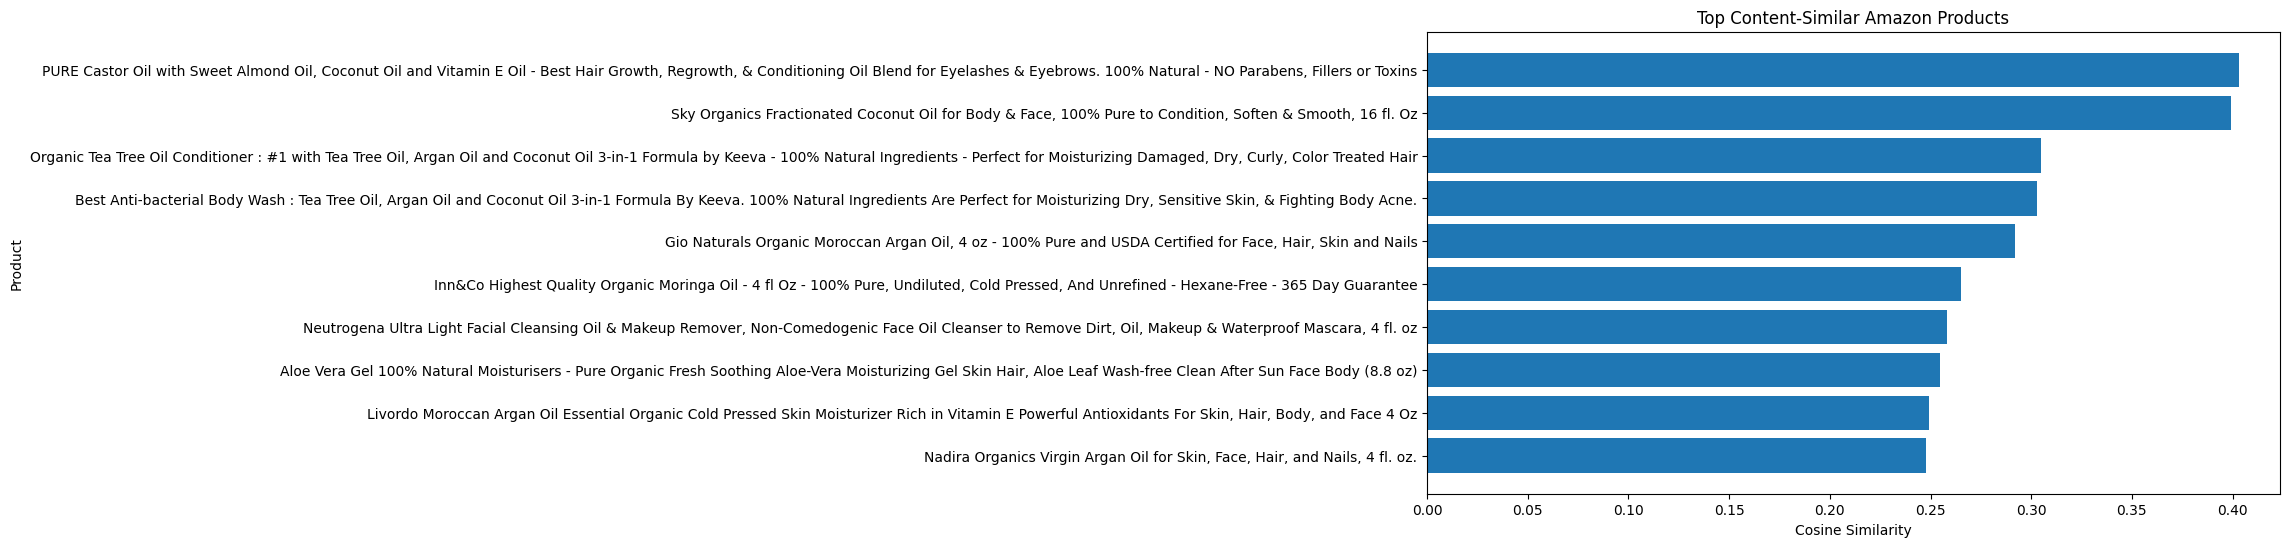

In [21]:
# 19. Plot Top-N similar products

if not similar_demo.empty:

    plot_data = (
        similar_demo
        .sort_values(
            "Cosine Similarity",
            ascending=True
        )
    )

    plt.figure(figsize=(11, 6))

    plt.barh(
        plot_data["title"],
        plot_data[
            "Cosine Similarity"
        ]
    )

    plt.xlabel(
        "Cosine Similarity"
    )

    plt.ylabel("Product")

    plt.title(
        "Top Content-Similar Amazon Products"
    )

    plt.tight_layout()
    plt.show()

## 20. Chronological train-test split


In [22]:
# 20. Chronological train-test split

# Latest interaction of each user -> test
# Earlier interactions            -> training history

test_indices = (
    reviews
    .groupby(
        "user_id"
    )["timestamp"]
    .idxmax()
)

is_test = reviews.index.isin(
    test_indices
)

test_data = reviews.loc[
    is_test
].copy()

train_data = reviews.loc[
    ~is_test
].copy()

print("\nTraining interactions:", len(train_data))
print("Testing interactions :", len(test_data))

train_by_user = train_data.groupby(
    "user_id",
    sort=False
)


Training interactions: 1008
Testing interactions : 159


## 21. Build a rating-weighted user content profile


In [23]:
# 21. Build a rating-weighted user content profile

def build_user_profile(
    user_id
):
    """
    Build a user's content profile from training interactions.

    user_mean:
        Mean training rating of the user.

    weight for product i:
        max(rating_i - user_mean, 0)

    profile:
        Weighted average of positively contributing product
        TF-IDF vectors.
    """

    if user_id not in train_by_user.groups:
        return None, pd.DataFrame(), np.nan

    history = (
        train_by_user
        .get_group(user_id)
        .copy()
    )

    history = history[
        history[
            "parent_asin"
        ].isin(
            product_to_row
        )
    ].copy()

    if history.empty:
        return None, history, np.nan

    user_mean = (
        history["rating"]
        .mean()
    )

    weights = np.maximum(
        history["rating"]
        .to_numpy(
            dtype=float
        )
        - user_mean,
        0.0
    )

    # Fallback for users whose ratings are all identical.
    if weights.sum() == 0:
        weights = (
            history["rating"]
            .to_numpy(
                dtype=float
            )
            / 5.0
        )

    positions = np.array(
        [
            product_to_row[
                product_id
            ]
            for product_id
            in history[
                "parent_asin"
            ]
        ],
        dtype=int
    )

    user_items = item_features[
        positions
    ]

    weighted_items = (
        user_items
        .multiply(
            weights[:, None]
        )
    )

    profile = (
        weighted_items
        .sum(axis=0)
    )

    profile = csr_matrix(
        profile
    )

    profile = profile / (
        weights.sum()
        + 1e-12
    )

    return (
        profile,
        history,
        user_mean
    )

## 22. Show strongest terms in a user profile


In [24]:
# 22. Show strongest terms in a user profile

def top_user_features(
    user_profile,
    top_n=15
):
    """
    Return the TF-IDF terms with the largest weights in a user's
    content profile.
    """

    if user_profile is None:
        return pd.DataFrame()

    values = (
        user_profile
        .toarray()
        .ravel()
    )

    positive_positions = np.where(
        values > 0
    )[0]

    if len(
        positive_positions
    ) == 0:
        return pd.DataFrame()

    n_keep = min(
        top_n,
        len(
            positive_positions
        )
    )

    local_values = values[
        positive_positions
    ]

    top_local = np.argpartition(
        local_values,
        -n_keep
    )[-n_keep:]

    top_positions = positive_positions[
        top_local
    ]

    top_positions = top_positions[
        np.argsort(
            values[
                top_positions
            ]
        )[::-1]
    ]

    return pd.DataFrame({
        "Feature": feature_names[
            top_positions
        ],
        "Profile Weight": values[
            top_positions
        ]
    })

## 23. Personalized Top-N recommendation function


In [25]:
# 23. Personalized Top-N recommendation function

def recommend_products(
    user_id,
    top_n=TOP_N
):
    """
    Score every unseen product by cosine similarity between the
    user's content profile and each product's TF-IDF vector.
    """

    (
        profile,
        history,
        user_mean
    ) = build_user_profile(
        user_id
    )

    if profile is None:
        return pd.DataFrame()

    scores = manual_cosine_scores(
        profile,
        item_features
    )

    seen_rows = [
        product_to_row[
            product_id
        ]
        for product_id
        in history[
            "parent_asin"
        ]
        if product_id
        in product_to_row
    ]

    scores[
        seen_rows
    ] = -np.inf

    candidate_rows = np.where(
        np.isfinite(scores)
    )[0]

    if len(candidate_rows) == 0:
        return pd.DataFrame()

    n_keep = min(
        top_n,
        len(candidate_rows)
    )

    candidate_scores = scores[
        candidate_rows
    ]

    top_local = np.argpartition(
        candidate_scores,
        -n_keep
    )[-n_keep:]

    top_rows = candidate_rows[
        top_local
    ]

    top_rows = top_rows[
        np.argsort(
            scores[
                top_rows
            ]
        )[::-1]
    ]

    result = metadata.iloc[
        top_rows
    ][
        [
            "parent_asin",
            "title",
            "main_category",
            "store"
        ]
    ].copy()

    result[
        "Content Similarity"
    ] = scores[
        top_rows
    ]

    return result.reset_index(
        drop=True
    )

## 24. Explain one recommendation


In [26]:
# 24. Explain one recommendation

def explain_recommendation(
    user_profile,
    product_id,
    top_n=8
):
    """
    Show the terms that contribute most strongly to the match
    between a user profile and one recommended product.
    """

    if (
        user_profile is None
        or product_id not in product_to_row
    ):
        return pd.DataFrame()

    product_vector = item_features[
        product_to_row[
            product_id
        ]
    ]

    contribution = (
        product_vector
        .multiply(
            user_profile
        )
        .toarray()
        .ravel()
    )

    positive_positions = np.where(
        contribution > 0
    )[0]

    if len(
        positive_positions
    ) == 0:
        return pd.DataFrame()

    n_keep = min(
        top_n,
        len(
            positive_positions
        )
    )

    values = contribution[
        positive_positions
    ]

    top_local = np.argpartition(
        values,
        -n_keep
    )[-n_keep:]

    top_positions = positive_positions[
        top_local
    ]

    top_positions = top_positions[
        np.argsort(
            contribution[
                top_positions
            ]
        )[::-1]
    ]

    return pd.DataFrame({
        "Matching Feature": feature_names[
            top_positions
        ],
        "Contribution": contribution[
            top_positions
        ]
    })

## 25. Choose a demo user from the filtered dataset


In [27]:
# 25. Choose a demo user from the filtered dataset

available_users = (
    train_data[
        "user_id"
    ]
    .drop_duplicates()
    .to_numpy()
)

if len(available_users) == 0:
    raise ValueError(
        "No users remain after filtering."
    )

demo_user_id = available_users[
    min(
        DEMO_USER_INDEX,
        len(
            available_users
        ) - 1
    )
]

## 26. Display the selected user's content profile


In [28]:
# 26. Display the selected user's content profile

(
    demo_profile,
    demo_history,
    demo_user_mean
) = build_user_profile(
    demo_user_id
)

print("\n" + "=" * 70)
print("SELECTED USER CONTENT PROFILE")
print("=" * 70)

print("User ID:")
print(demo_user_id)

print(
    "Training interactions:",
    len(demo_history)
)

print(
    "Mean training rating:",
    round(
        demo_user_mean,
        3
    )
)

demo_features = top_user_features(
    demo_profile,
    top_n=15
)

display(demo_features)


SELECTED USER CONTENT PROFILE
User ID:
AGZZXSMMS4WRHHJRBUJZI4FZDHKQ
Training interactions: 6
Mean training rating: 5.0


,Feature,Profile Weight
0,hair,0.256466
1,clips,0.184391
2,pcs,0.118174
3,barrettes,0.083036
4,scrunchies,0.081258
5,snap,0.079125
6,rhinestone,0.079097
7,nail,0.068946
8,file,0.068918
9,women,0.061270


## 27. Visualize strongest user-profile features


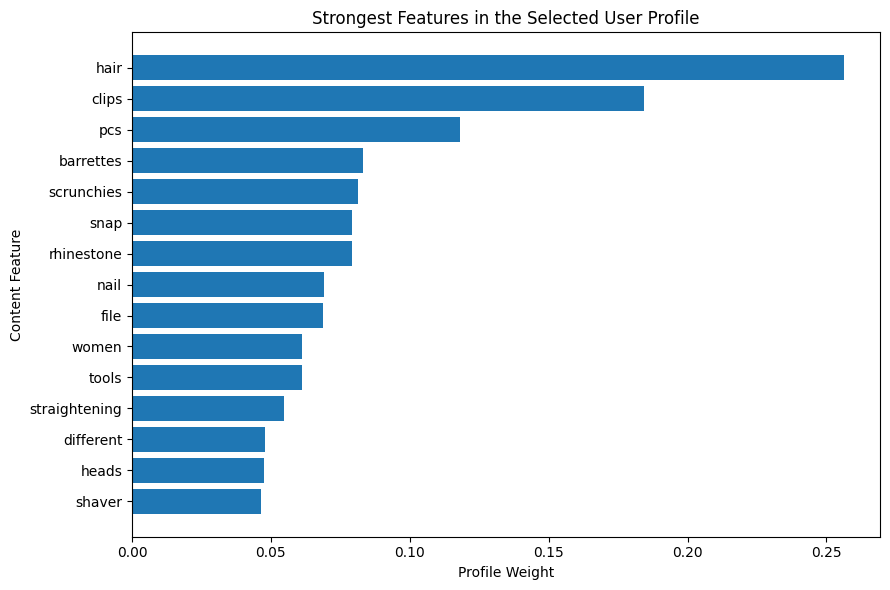

In [29]:
# 27. Visualize strongest user-profile features

if not demo_features.empty:

    plot_features = (
        demo_features
        .sort_values(
            "Profile Weight",
            ascending=True
        )
    )

    plt.figure(figsize=(9, 6))

    plt.barh(
        plot_features["Feature"],
        plot_features[
            "Profile Weight"
        ]
    )

    plt.xlabel(
        "Profile Weight"
    )

    plt.ylabel(
        "Content Feature"
    )

    plt.title(
        "Strongest Features in the Selected User Profile"
    )

    plt.tight_layout()
    plt.show()

## 28. Generate personalized Top-N recommendations


In [30]:
# 28. Generate personalized Top-N recommendations

recommendations = recommend_products(
    demo_user_id,
    top_n=TOP_N
)

print("\n" + "=" * 70)

print(
    f"TOP {TOP_N} AMAZON CONTENT-BASED "
    "RECOMMENDATIONS"
)

print("=" * 70)

display(recommendations)


TOP 10 AMAZON CONTENT-BASED RECOMMENDATIONS


,parent_asin,title,main_category,store,Content Similarity
0,B07VWLSNYN,"UMICKOO Hair Straightener,Upgraded Flat Iron f...",All Beauty,UMIKOO,0.376721
1,B07DQGT2JH,4 Pieces Large Grip Octopus Clip No Slip Spide...,All Beauty,Bememo,0.359977
2,B0B4KS62Z8,L'ANGE HAIR Rubber Sectioning Hair Clips | Nar...,All Beauty,L'ANGE HAIR,0.320102
3,B07DPKZPRH,PARWIN Infrared Flat Iron 1 1/4 Inch Digital H...,All Beauty,PARWIN,0.317584
4,B07QYD1J5C,"AIRUISI Ceramic Flat Iron for Hair, Profession...",All Beauty,AIRUISI,0.304889
5,B07HR754WV,NeWisdom 72 PCS Toddler Girls Hair Accessory S...,All Beauty,NeWisdom,0.298016
6,B0919LJ9WT,"18 Pack Hair Ties,Spiral elastics, Multi Color...",All Beauty,Gomayee,0.288405
7,B075D96DZK,30 PCS Blue Hair Care Rollers Hair Curlers Sil...,All Beauty,ONEONEY,0.283263
8,B079R2VWNX,Spring Twist hair 3PCS Crochet Braids Hair Syn...,All Beauty,Becolor,0.270376
9,B00AX3YNPC,Braun Silk Epil Female Epilator Se7921spa 1 Count,All Beauty,Braun,0.266181


## 29. Visualize personalized recommendations


/tmp/ipykernel_2085/3430944648.py:36: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


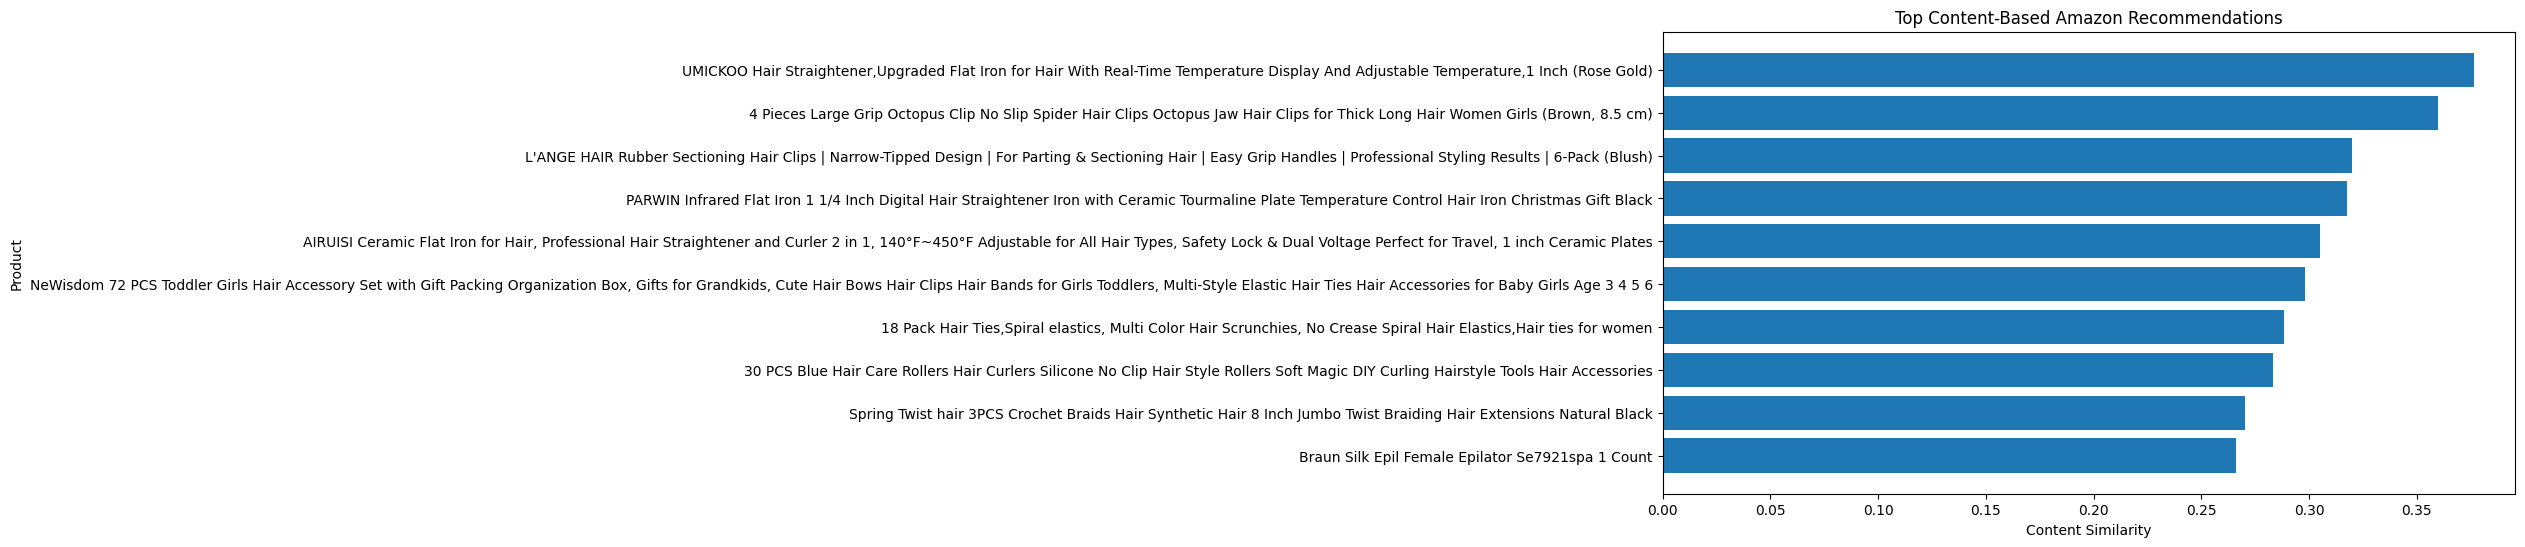

In [31]:
# 29. Visualize personalized recommendations

if not recommendations.empty:

    plot_recommendations = (
        recommendations
        .sort_values(
            "Content Similarity",
            ascending=True
        )
    )

    plt.figure(figsize=(11, 6))

    plt.barh(
        plot_recommendations[
            "title"
        ],
        plot_recommendations[
            "Content Similarity"
        ]
    )

    plt.xlabel(
        "Content Similarity"
    )

    plt.ylabel(
        "Product"
    )

    plt.title(
        "Top Content-Based Amazon Recommendations"
    )

    plt.tight_layout()
    plt.show()

## 30. Explain the first recommendation


In [32]:
# 30. Explain the first recommendation

if (
    demo_profile is not None
    and not recommendations.empty
):

    first_product_id = (
        recommendations
        .iloc[0][
            "parent_asin"
        ]
    )

    first_product_title = (
        recommendations
        .iloc[0][
            "title"
        ]
    )

    explanation = (
        explain_recommendation(
            demo_profile,
            first_product_id,
            top_n=8
        )
    )

    print("\n" + "=" * 70)
    print("RECOMMENDATION EXPLANATION")
    print("=" * 70)

    print(
        "Recommended product:"
    )

    print(
        first_product_title
    )

    display(
        explanation
    )


RECOMMENDATION EXPLANATION
Recommended product:
UMICKOO Hair Straightener,Upgraded Flat Iron for Hair With Real-Time Temperature Display And Adjustable Temperature,1 Inch (Rose Gold)


,Matching Feature,Contribution
0,hair,0.112448
1,temperature,0.013856
2,clips,0.013458
3,straightener,0.008161
4,adjustable,0.004511
5,floating,0.003989
6,display,0.003835
7,different,0.002997


## 31. Prepare ranking evaluation


In [33]:
# 31. Prepare ranking evaluation
#
# Only held-out ratings >= 4.0 are treated as relevant.

eligible_test = test_data[
    test_data[
        "rating"
    ] >= RELEVANCE_THRESHOLD
].copy()

eligible_test = eligible_test[
    eligible_test[
        "parent_asin"
    ].isin(
        product_to_row
    )
]

eligible_test = eligible_test[
    eligible_test[
        "user_id"
    ].isin(
        train_by_user.groups
    )
]

if (
    MAX_EVAL_USERS is not None
    and len(
        eligible_test
    ) > MAX_EVAL_USERS
):

    eligible_test = (
        eligible_test
        .sample(
            n=MAX_EVAL_USERS,
            random_state=EVAL_RANDOM_STATE
        )
        .sort_values(
            "user_id"
        )
    )

print(
    "\nUsers selected for ranking evaluation:",
    len(
        eligible_test
    )
)


Users selected for ranking evaluation: 133


## 32. Evaluate Hit Rate, MRR and NDCG


In [34]:
# 32. Evaluate Hit Rate, MRR and NDCG

ranking_rows = []

for number, row in enumerate(
    eligible_test.itertuples(),
    start=1
):

    (
        profile,
        history,
        _
    ) = build_user_profile(
        row.user_id
    )

    if profile is None:
        continue

    scores = manual_cosine_scores(
        profile,
        item_features
    )

    seen_rows = [
        product_to_row[
            product_id
        ]
        for product_id
        in history[
            "parent_asin"
        ]
        if product_id
        in product_to_row
    ]

    scores[
        seen_rows
    ] = -np.inf

    target_row = product_to_row[
        row.parent_asin
    ]

    target_score = scores[
        target_row
    ]

    if not np.isfinite(
        target_score
    ):
        continue

    rank = (
        int(
            np.sum(
                scores
                > target_score
            )
        )
        + 1
    )

    hit = int(
        rank <= RANKING_K
    )

    reciprocal_rank = (
        1.0 / rank
        if rank <= RANKING_K
        else 0.0
    )

    ndcg = (
        1.0
        / np.log2(
            rank + 1
        )
        if rank <= RANKING_K
        else 0.0
    )

    ranking_rows.append({
        "user_id": row.user_id,
        "parent_asin": row.parent_asin,
        "Target Rating": row.rating,
        "Target Rank": rank,
        f"Hit@{RANKING_K}": hit,
        f"RR@{RANKING_K}": reciprocal_rank,
        f"NDCG@{RANKING_K}": ndcg
    })

    if (
        number == 1
        or number % 50 == 0
    ):
        print(
            f"Evaluated {number} / "
            f"{len(eligible_test)} users"
        )


ranking_results = pd.DataFrame(
    ranking_rows
)

if len(
    ranking_results
) > 0:

    hit_rate = (
        ranking_results[
            f"Hit@{RANKING_K}"
        ]
        .mean()
    )

    mrr_at_k = (
        ranking_results[
            f"RR@{RANKING_K}"
        ]
        .mean()
    )

    ndcg_at_k = (
        ranking_results[
            f"NDCG@{RANKING_K}"
        ]
        .mean()
    )

else:

    hit_rate = np.nan
    mrr_at_k = np.nan
    ndcg_at_k = np.nan


print("\n" + "=" * 70)
print("AMAZON CONTENT-BASED RANKING EVALUATION")
print("=" * 70)

print(
    "Evaluated users:",
    len(
        ranking_results
    )
)

print(
    f"Hit Rate@{RANKING_K}:",
    round(
        hit_rate,
        4
    )
)

print(
    f"MRR@{RANKING_K}:",
    round(
        mrr_at_k,
        4
    )
)

print(
    f"NDCG@{RANKING_K}:",
    round(
        ndcg_at_k,
        4
    )
)

display(
    ranking_results.head(15)
)

Evaluated 1 / 133 users
Evaluated 50 / 133 users
Evaluated 100 / 133 users

AMAZON CONTENT-BASED RANKING EVALUATION
Evaluated users: 133
Hit Rate@10: 0.0602
MRR@10: 0.017
NDCG@10: 0.0272


,user_id,parent_asin,Target Rating,Target Rank,Hit@10,RR@10,NDCG@10
0,AFEQMQUDCRRXIGC3CEES2AJOLZHQ,B00KECQ8BY,5,364,0,0.0,0.0
1,AEG2APVZSEZULB4ENINTBABQF7BQ,B00VXEQ0WO,5,11,0,0.0,0.0
2,AFXL65ISDBHR2DP7NROTUGMZAKIA,B00XZA42TW,5,135,0,0.0,0.0
3,AEWSBI63F74S3HF67N6BUCRNLAWQ,B015TJJYXU,5,243,0,0.0,0.0
4,AEVVEYZF4MQDPC2BY2HBBNGZRYHA,B019NBEIKY,5,450,0,0.0,0.0
5,AGBF546BGRZAFFEIPWP3FIPE3F3A,B0167XBHO6,5,158,0,0.0,0.0
6,AFDCRSWD5SXZ7YXKIKZ5LHUUT5NA,B00MZT4UEG,5,189,0,0.0,0.0
7,AE644JVRCJETRVH5MHJ55NHVPOFQ,B01CUPHRQM,5,86,0,0.0,0.0
8,AHETDGASODBTH5UNKJMMGGE6M25Q,B01G45HX18,5,296,0,0.0,0.0
9,AFOYDZTIH27IJJKIXXKAPVRFQ2OQ,B0186AH6VG,4,146,0,0.0,0.0
